## Cadenas de Markov

Una **Cadena de Markov de primer orden** es un modelo probabilístico donde la transición a un estado futuro depende únicamente del estado actual y no de la secuencia de estados que le precedieron (propiedad de Markov).

Aplicado al modelado y generación de texto, definimos:
- El **Espacio de Estados** ${S} = \{w_1, w_2, \dots, w_N\}$ como el vocabulario único obtenido del corpus.
- El estado en el tiempo $t$ como la variable aleatoria $W_t$ que toma un valor dentro de ${S}$.

La **probabilidad de transición condicional** de pasar de la palabra $w_i$ (en el paso $t-1$) a la palabra $w_j$ (en el paso $t$) se define matemáticamente como:

$$P(W_t = w_j \mid W_{t-1} = w_i) = \frac{\text{count}(w_i, w_j)}{\sum_{w \in {S}} \text{count}(w_i, w)}$$

Donde:
- $\text{count}(w_i, w_j)$ representa la frecuencia con la que la palabra $w_j$ aparece inmediatamente después de $w_i$ en el corpus.
- El denominador es la suma de las transiciones desde $w_i$ hacia cualquier otra palabra $w$ del vocabulario (frecuencia total de aparición de $w_i$ seguida de algún término).

La unión de todas estas probabilidades forma una **Matriz de Transición de Probabilidades** $\mathbf{P} \in \mathbb{R}^{N \times N}$, donde cada fila representa una distribución de probabilidad que suma 1:

$$\sum_{j=1}^{N} P_{i,j} = 1 \quad \forall i$$

### Entendiendo las Cadenas de Markov paso a paso con una estrofa

Para ver exactamente de dónde salen los números de la matriz de transición, analicemos la primera estrofa del *Martín Fierro*:

> *"Aquí me pongo a cantar al compás de la vigüela que el hombre que lo desvela una pena estraordinaria como la ave solitaria con el cantar se consuela."*

#### Paso 1: Extracción de transiciones (pares de bigramas consecutivos)
Recorremos la secuencia de palabras de izquierda a derecha registrando cada transición $(w_t \to w_{t+1})$:

1. $(\text{aquí} \to \text{me})$
2. $(\text{me} \to \text{pongo})$
3. $(\text{pongo} \to \text{a})$
4. $(\text{a} \to \text{cantar})$
5. $(\text{cantar} \to \text{al})$
6. $(\text{al} \to \text{compás})$
7. $(\text{compás} \to \text{de})$
8. $(\text{de} \to \text{la})$
9. $(\text{la} \to \text{vigüela})$
10. $(\dots)$
11. $(\text{el} \to \text{cantar})$
12. $(\text{cantar} \to \text{se})$
13. $(\text{se} \to \text{consuela})$

#### Paso 2: Conteo de frecuencias desde una palabra pivote
Tomemos como estado actual la palabra **"cantar"** en esta sola estrofa. ¿A dónde salta "cantar"?
- En la línea 5: transiciona a **"al"** (1 vez: *"cantar al compás"*).
- En la línea 12: transiciona a **"se"** (1 vez: *"el cantar se consuela"*).

Total de salidas desde la palabra *"cantar"*:
$$\text{Total}(\text{"cantar"}) = 1 + 1 = 2$$

#### Paso 3: Cálculo de probabilidades condicionales (Fila de la Matriz)
Normalizamos dividiendo cada conteo entre el total de transiciones desde esa palabra:

$$P(W_{t+1} = \text{"al"} \mid W_t = \text{"cantar"}) = \frac{\text{count}(\text{"cantar"}, \text{"al"})}{\text{Total}(\text{"cantar"})} = \frac{1}{2} = 0.50 \quad (50\%)$$

$$P(W_{t+1} = \text{"se"} \mid W_t = \text{"cantar"}) = \frac{\text{count}(\text{"cantar"}, \text{"se"})}{\text{Total}(\text{"cantar"})} = \frac{1}{2} = 0.50 \quad (50\%)$$

$$P(W_{t+1} = w \mid W_t = \text{"cantar"}) = 0.00 \quad \forall w \notin \{\text{"al"}, \text{"se"}\}$$

La suma de toda la fila es estrictamente 1:
$$\sum_{j=1}^{N} P_{i,j} = 0.50 + 0.50 = 1.00$$

#### Paso 4: Muestreo para generar texto
Cuando la cadena se encuentra en el estado *"cantar"*, generamos un número pseudoaleatorio $u \in [0, 1)$:
- Si $u < 0.50 \implies$ la siguiente palabra será **"al"**.
- Si $u \ge 0.50 \implies$ la siguiente palabra será **"se"**.

### 📊 Representación matricial y vectorial de la Cadena de Markov

La matriz `P` contiene las probabilidades de transición entre palabras.


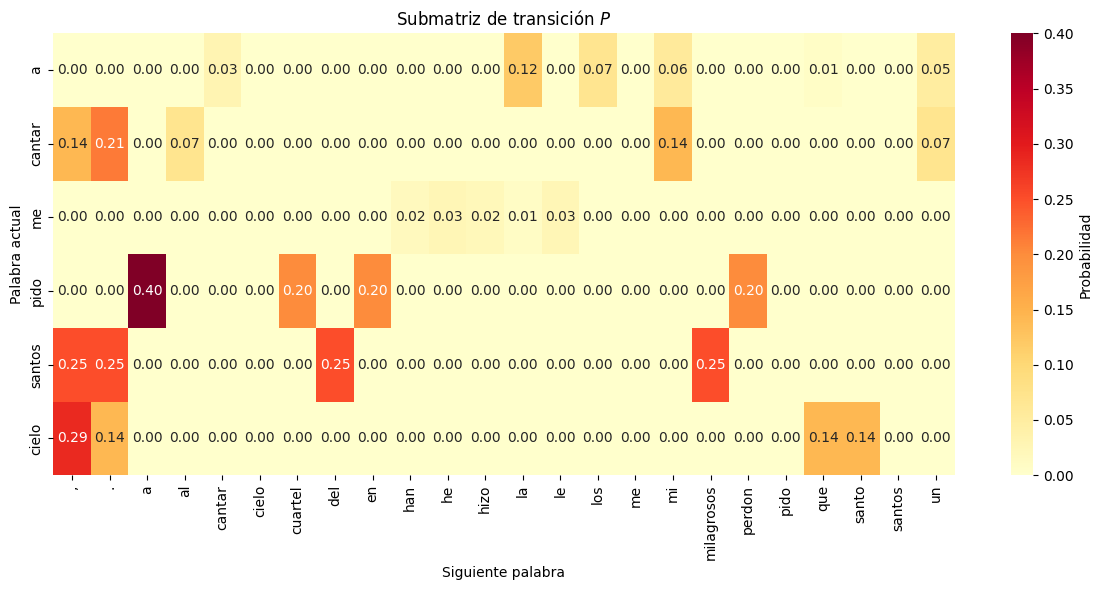


Si el estado actual es una palabra, su representación vectorial es un vector *one-hot*. Por ejemplo, para `['a', 'cantar', 'me', 'pido', 'santos', 'cielo']`, el estado `pido` se representa como `[0, 0, 0, 1, 0, 0]`. Al multiplicarlo por la matriz de transición obtenemos la distribución de probabilidad del siguiente estado:

$$\boldsymbol{\pi}_{t+1}=\boldsymbol{\pi}_t P$$

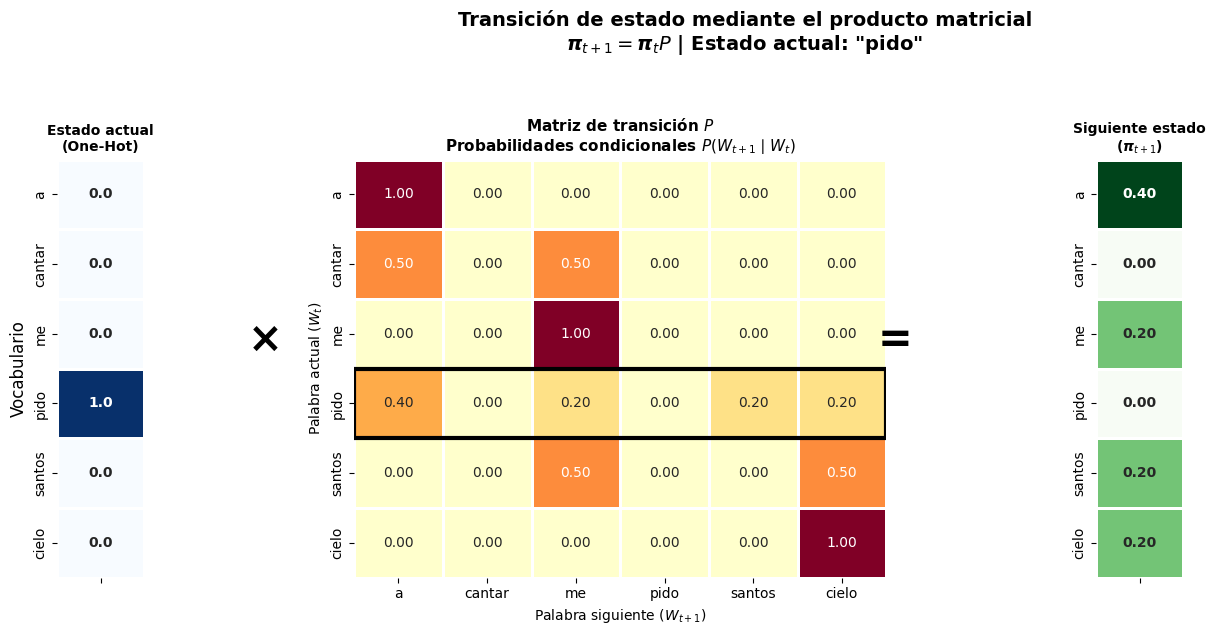

Al multiplicar el vector One-Hot del estado *'pido'* por la matriz de transición P,
se obtiene la fila 3 de P, que representa la distribución de probabilidad de la siguiente palabra

In [ ]:
!pip install gensim==4.4.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 46.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import warnings
import random
import requests
import unicodedata
import torch
import torch.nn as nn
import torch.nn.functional as F
import logging
import time

from gensim.models import Word2Vec
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from collections import defaultdict, Counter
from scipy.stats import gaussian_kde
from typing import Callable, Iterable
from copy import deepcopy
from pydantic import BaseModel, PositiveInt

In [ ]:
class Corpus():
  def __init__(self, documents):
    self.raw_documents = documents

  def get_raw_documents(self):
    return self.raw_documents

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.raw_documents))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.raw_documents[i][:250]}')

In [ ]:
class DocumentsCleaner():

    @staticmethod
    def _transform(
        documents: Iterable[str],
        function: Callable[[str], str],
        *,
        discard_empty: bool = False
    ) -> list[str]:
        """Aplica una transformación y devuelve una nueva lista."""
        result = [function(document) for document in documents]
        return [doc for doc in result if doc] if discard_empty else result

    def delete_init_final_chars(self, documents):
        """Elimina espacios al inicio y al final y descarta documentos vacíos."""
        return self._transform(
            documents, str.strip, discard_empty=True
        )

    def to_lower_case(self, documents):
        """Convierte los documentos a minúsculas."""
        return self._transform(documents, str.lower)

    def delete_accents(self, documents):
        """Elimina los diacríticos de los documentos."""
        def remove_accents(document):
            return ''.join(
                char
                for char in unicodedata.normalize('NFD', document)
                if unicodedata.category(char) != 'Mn'
            )

        return self._transform(documents, remove_accents)

    def conserve_letters_numbers_spaces_and_signs(self, documents):
        """Conserva los caracteres permitidos."""
        pattern = re.compile(r'[^a-zñ0-9\s.,;:¿?¡!"“”\'()\-—…]')

        return self._transform(
            documents,
            lambda document: pattern.sub('', document)
        )

    def normalize_multiple_spaces(self, documents):
        """Reduce los espacios consecutivos a uno solo."""
        return self._transform(
            documents,
            lambda document: re.sub(r'\s+', ' ', document).strip()
        )

    def conserve_documents_with_than_words(self, documents, n=5):
        """Conserva documentos con más de n palabras."""
        return [
            document
            for document in documents
            if document and len(document.split()) > n
        ]

    def apply_rgx(self, documents, rgx):
        """Descarta documentos que coinciden con el patrón
        o que tienen menos de dos líneas.
        """
        pattern = re.compile(rgx)

        return [
            document
            for document in documents
            if not pattern.match(document)
            and len(document.split('\n')) >= 2
        ]

In [ ]:
class Tokenizer():

  def tokenize(self, documents):
    """
    Separa palabras, números y signos de puntuación
    """
    tokenized_documents = []

    for i, doc in enumerate(documents):
        tokens = re.findall(r'\w+|[^\w\s]', doc, flags=re.UNICODE)
        tokenized_documents.append(tokens)

    self.tokens = tokenized_documents

  def get_tokens(self):
    return self.tokens

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.tokens))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.tokens[i][:250]}')

In [ ]:
class TfIdf():

    def __init__(self, documents):
        self.documents = tuple(documents)

        self.vectorizer = TfidfVectorizer()
        self.tfidf_matrix = self.vectorizer.fit_transform(
            self.documents
        )

        self.tfidf_vocab = tuple(
            self.vectorizer.get_feature_names_out()
        )

        self.vocab_to_index = {
            word: index
            for index, word in enumerate(self.tfidf_vocab)
        }

    def map_vocab_to_index(self):
        """Devuelve el mapeo de palabras a columnas."""
        return self.vocab_to_index.copy()

    def get_word_vector(self, word):
        """Devuelve los pesos TF-IDF de una palabra en cada documento."""
        index = self.vocab_to_index.get(word)

        if index is None:
            raise ValueError(
                f"La palabra {word!r} no está en el vocabulario TF-IDF."
            )

        return self.tfidf_matrix[:, index].toarray().ravel()

    def search_similar(self, query, top_k=3):
        """Devuelve los documentos más similares a la consulta."""
        if top_k < 1:
            raise ValueError("top_k debe ser mayor que cero.")

        query_vector = self.vectorizer.transform([query])

        # La consulta no contiene términos del vocabulario.
        if query_vector.nnz == 0:
            return []

        similarities = cosine_similarity(
            query_vector,
            self.tfidf_matrix
        ).ravel()

        top_indices = np.argsort(
            -similarities,
            kind="stable"
        )[:top_k]

        return [
            (int(index), float(similarities[index]))
            for index in top_indices
            if similarities[index] > 0
        ]

    def to_pandas_df(self):
        """Convierte la matriz TF-IDF en un DataFrame."""
        return pd.DataFrame(
            self.tfidf_matrix.toarray(),
            columns=self.tfidf_vocab,
            index=[
                f"Estrofa {i + 1}"
                for i in range(len(self.documents))
            ]
        )

In [ ]:
class Word2VecParams(BaseModel):
  vector_size: PositiveInt = 50
  window: PositiveInt = 4
  min_count: PositiveInt = 2
  negative: PositiveInt = 10
  epochs: PositiveInt = 100
  workers: PositiveInt = 4
  seed: int = 42

In [ ]:
class Word2Vector():
    """Entrena y consulta un modelo Word2Vec."""

    def __init__(
        self,
        documents,
        hiper_params: Word2VecParams,
        verbose: bool = False
    ):

        self.documents = tuple(tuple(doc) for doc in documents)
        self._logger = logging.getLogger(__name__)

        if verbose:
            print("=" * 60)
            print("ENTRENANDO MODELO WORD2VEC")
            print(
                f"Dimensión={hiper_params.vector_size} | Ventana={hiper_params.window} "
                f"| Épocas={hiper_params.epochs}"
            )
            print("=" * 60)

        start_time = time.perf_counter()

        self.model = Word2Vec(
            sentences=self.documents,
            vector_size=hiper_params.vector_size,
            window=hiper_params.window,
            min_count=hiper_params.min_count,
            negative=hiper_params.negative,
            epochs=hiper_params.epochs,
            workers=hiper_params.workers,
            seed=hiper_params.seed,
        )

        self.words = tuple(self.model.wv.index_to_key)
        self.vocab_to_index = {
            word: i for i, word in enumerate(self.words)
        }

        if verbose:
            elapsed = time.perf_counter() - start_time
            print(f"Entrenamiento completado en {elapsed:.2f} s")
            print(f"Vocabulario: {len(self.words):,} palabras")
            print("=" * 60)

    @property
    def vectors(self):
        """Devuelve una copia de la matriz de embeddings."""
        return self.model.wv.vectors.copy()

    def get_embeddings_data(self):
        """Devuelve el vocabulario y una copia de sus embeddings."""
        return self.words, self.vectors

    def get_word_vector(self, word):
        """Obtiene el embedding de una palabra."""
        if word not in self.model.wv:
            raise ValueError(
                f"La palabra {word!r} no está en el vocabulario Word2Vec."
            )

        return self.model.wv[word].copy()

    def map_vocab_to_index(self):
        """Devuelve el índice de cada palabra del vocabulario."""
        return self.vocab_to_index.copy()

    def print_summary(self, sample_size=20):
        """Muestra las dimensiones y una muestra del vocabulario."""
        if sample_size < 0:
            raise ValueError("sample_size no puede ser negativo.")

        vocab_size = len(self.words)
        vector_size = self.model.wv.vector_size

        print("=" * 60)
        print("RESUMEN DEL MODELO WORD2VEC")
        print("=" * 60)
        print(f"Vocabulario: {vocab_size:,} palabras")
        print(f"Dimensión: {vector_size}D")
        print(f"Matriz: ({vocab_size}, {vector_size})")
        print("-" * 60)
        print(f"Primeras {min(sample_size, vocab_size)} palabras:")

        for i, word in enumerate(self.words[:sample_size], start=1):
            print(f"{i:>4}. {word}")

        print("=" * 60)

    def compute_vector_analogy(
        self, positive, negative=(), top_n=10, prints=True
    ):
        """Calcula analogías vectoriales y devuelve resultados y ausentes."""
        if top_n < 1:
            raise ValueError("top_n debe ser mayor que cero.")

        positive = tuple(positive)
        negative = tuple(negative)
        required_words = positive + negative

        missing_words = list(dict.fromkeys(
            word for word in required_words
            if word not in self.model.wv
        ))

        if missing_words:
            return None, missing_words

        if not positive:
            raise ValueError("Se necesita al menos una palabra positiva.")

        results = self.model.wv.most_similar(
            positive=list(positive),
            negative=list(negative),
            topn=top_n,
        )

        if prints:
            self._print_analogy_results(
                positive, negative, results
            )

        return results, []

    def gen_text(
        self,
        seed,
        length=15,
        temperature=0.7,
        top_k=8,
        random_seed=42,
    ):
        """Genera una secuencia explorando vecinos semánticos."""
        if length < 1:
            raise ValueError("length debe ser mayor que cero.")
        if temperature <= 0:
            raise ValueError("temperature debe ser mayor que cero.")
        if top_k < 1:
            raise ValueError("top_k debe ser mayor que cero.")

        current_word = seed.strip().lower()

        if current_word not in self.model.wv:
            raise ValueError(
                f"La palabra {seed!r} no está en el vocabulario Word2Vec."
            )

        rng = np.random.default_rng(random_seed)
        result = [current_word]

        for _ in range(length - 1):
            neighbors = self.model.wv.most_similar(
                current_word,
                topn=min(top_k, len(self.words) - 1),
            )

            if not neighbors:
                break

            candidates, similarities = zip(*neighbors)
            probabilities = self._softmax(
                similarities, temperature
            )

            current_word = rng.choice(
                candidates, p=probabilities
            )
            result.append(current_word)

        return " ".join(result)

    def to_pandas_df(self):
        """Devuelve los embeddings en un DataFrame."""
        return pd.DataFrame(
            self.vectors,
            index=self.words,
            columns=[
                f"Dim_{i + 1}"
                for i in range(self.model.wv.vector_size)
            ],
        )

    @staticmethod
    def _softmax(values, temperature=1.0):
        """Calcula softmax con temperatura y estabilidad numérica."""
        if temperature <= 0:
            raise ValueError("temperature debe ser mayor que cero.")

        logits = np.asarray(values, dtype=float) / temperature
        logits -= logits.max()
        exp_logits = np.exp(logits)

        return exp_logits / exp_logits.sum()

    @staticmethod
    def _print_analogy_results(positive, negative, results):
        equation = " + ".join(map(repr, positive))

        if negative:
            equation += " - " + " - ".join(map(repr, negative))

        print("=" * 60)
        print("ANALOGÍA VECTORIAL")
        print(equation)
        print("-" * 60)

        for word, similarity in results:
            bar = "█" * int(max(0, similarity) * 10)
            print(f"{word:<22} {similarity:>8.4f}  {bar}")

        print("=" * 60)

In [ ]:
class MarkovModel():
    """
    Modelo de Markov de orden n.

    La generación utiliza explícitamente la operación:
        vector_one_hot @ matriz_transicion = probabilidades_siguientes

    Esta implementación prioriza la claridad educativa sobre la eficiencia.
    """

    def __init__(self, documents, n=1):
        if not isinstance(n, int) or isinstance(n, bool) or n < 1:
            raise ValueError("n debe ser un entero mayor o igual a 1.")

        self.n = n
        self._transition_counts = defaultdict(Counter)

        # Construir los conteos de transición.
        for document in documents:
            for i in range(len(document) - n):
                context_words = document[i:i + n]
                context = self._make_context(context_words)
                next_word = document[i + n]

                self._transition_counts[context][next_word] += 1

        self._base_probs = self._counts_to_probabilities(
            self._transition_counts
        )
        self._transition_probs = deepcopy(self._base_probs)
        self._modulation = None

        # Vocabularios ordenados para mantener la correspondencia
        # entre vectores one-hot, filas y columnas de la matriz.
        self._refresh_vocabularies()

    def _make_context(self, words):
        """Representa el contexto como str para n=1 o tuple para n>1."""
        return words[0] if self.n == 1 else tuple(words)

    def _refresh_vocabularies(self):
        """
        Actualiza los vocabularios según las probabilidades actuales.
        Conserva el orden de inserción de los contextos.
        """
        self.context_vocab = tuple(self._transition_probs.keys())

        self.next_word_vocab = tuple(sorted({
            word
            for successors in self._transition_probs.values()
            for word in successors
        }))

        self.context_to_index = {
            context: i
            for i, context in enumerate(self.context_vocab)
        }

        self.next_word_to_index = {
            word
            for word in self.next_word_vocab
        }
        self.next_word_to_index = {
            word: i
            for i, word in enumerate(self.next_word_vocab)
        }

    @property
    def transition_probs(self):
        """Devuelve una copia de las probabilidades actuales."""
        return deepcopy(self._transition_probs)

    @property
    def transition_counts(self):
        """Devuelve una copia de los conteos de transición."""
        return deepcopy(dict(self._transition_counts))

    @property
    def already_moduled(self):
        """Indica si se ha aplicado una modulación."""
        return self._modulation is not None

    @staticmethod
    def _counts_to_probabilities(counts):
        """Convierte los conteos en probabilidades condicionales."""
        probabilities = {}

        for context, successors in counts.items():
            total = sum(successors.values())

            if total:
                probabilities[context] = {
                    word: count / total
                    for word, count in successors.items()
                }

        return probabilities

    def _normalize_context(self, context):
        """Normaliza un contexto según el orden del modelo."""
        if self.n == 1:
            if isinstance(context, str):
                return context.lower().strip()

            if len(context) != 1:
                raise ValueError(
                    "Para n=1, el contexto debe contener una palabra."
                )

            return context[0].lower().strip()

        if isinstance(context, str):
            words = context.lower().split()
        else:
            words = [word.lower().strip() for word in context]

        if len(words) != self.n:
            raise ValueError(
                f"El contexto debe contener exactamente {self.n} palabras."
            )

        return tuple(words)

    def get_word_transitions(self, context):
        """Devuelve una copia de los conteos de un contexto."""
        context = self._normalize_context(context)

        return Counter(self._transition_counts.get(context, {}))

    # ---------------------------------------------------------
    # REPRESENTACIÓN ONE-HOT Y MATRIZ DE TRANSICIÓN
    # ---------------------------------------------------------

    def get_context_onehot(self, context):
        """
        Representa un contexto mediante un vector one-hot.

        La posición del 1 identifica la fila correspondiente
        al contexto en la matriz de transición.
        """
        context = self._normalize_context(context)

        if context not in self.context_to_index:
            raise ValueError(
                f"El contexto {self._format_context(context)!r} "
                "no existe en el modelo."
            )

        vector = np.zeros(
            len(self.context_vocab),
            dtype=np.int8,
        )

        vector[self.context_to_index[context]] = 1

        return vector

    def get_transition_matrix(self):
        """
        Devuelve la matriz P de transición.

        Filas: contextos.
        Columnas: palabras siguientes.
        """
        matrix = np.zeros(
            (len(self.context_vocab), len(self.next_word_vocab)),
            dtype=float,
        )

        for context, successors in self._transition_probs.items():
            row = self.context_to_index[context]

            for word, probability in successors.items():
                col = self.next_word_to_index[word]
                matrix[row, col] = probability

        return matrix.copy(), self.context_vocab, self.next_word_vocab

    def get_next_word_probabilities(self, context, verbose=False):
        """
        Calcula las probabilidades mediante:

            one_hot(context) @ transition_matrix

        Se utiliza la multiplicación matricial explícitamente
        con fines didácticos.
        """
        one_hot = self.get_context_onehot(context)
        matrix, _, words = self.get_transition_matrix()

        # (1 x número de contextos) @
        # (número de contextos x número de palabras)
        probabilities = one_hot @ matrix

        if verbose:
            print("Vector one-hot:")
            print(one_hot)

            print("\nMatriz de transición:")
            print(pd.DataFrame(
                matrix,
                index=[
                    self._format_context(c)
                    for c in self.context_vocab
                ],
                columns=words,
            ))

            print("\nResultado de la multiplicación:")
            print(probabilities)

        return {
            word: float(probability)
            for word, probability in zip(words, probabilities)
        }

    # ---------------------------------------------------------
    # MODULACIÓN DE PROBABILIDADES
    # ---------------------------------------------------------

    def _apply_weights(self, weight_function, method):
        """Podera y normaliza las probabilidades de cada contexto."""
        if self.already_moduled:
            raise RuntimeError(
                f"Ya se aplicó la modulación {self._modulation!r}."
            )

        updated = {}

        for context, successors in self._base_probs.items():
            weighted = {
                word: probability * weight_function(word)
                for word, probability in successors.items()
            }

            total = sum(weighted.values())

            if total > 0:
                updated[context] = {
                    word: value / total
                    for word, value in weighted.items()
                }
            else:
                updated[context] = successors.copy()

        self._transition_probs = updated
        self._modulation = method
        self._refresh_vocabularies()

    def module_transition_base_probs_with_idf(
        self,
        tfidf_representation,
        bias=1.0,
    ):
        """Modula las transiciones usando el IDF de la palabra destino."""
        if bias < 0:
            raise ValueError("bias no puede ser negativo.")

        vectorizer = tfidf_representation.vectorizer

        idf = dict(zip(
            vectorizer.get_feature_names_out(),
            vectorizer.idf_,
        ))

        self._apply_weights(
            lambda word: idf.get(word, 1.0) ** bias,
            "idf",
        )

    def module_transition_base_probs_with_w2v(
        self,
        w2v_representation,
        guide_word,
        beta=1.0,
    ):
        """Modula las transiciones usando similitud semántica con Word2Vec."""
        if beta < 0:
            raise ValueError("beta no puede ser negativo.")

        model = w2v_representation.model.wv
        guide_word = guide_word.lower().strip()

        if guide_word not in model:
            raise ValueError(
                f"La palabra guía {guide_word!r} "
                "no está en el vocabulario de Word2Vec."
            )

        def semantic_weight(word):
            if word not in model:
                return 0.01

            similarity = float(model.similarity(word, guide_word))

            # Transformación del intervalo [-1, 1] a [0, 1].
            similarity = (similarity + 1.0) / 2.0

            return similarity ** beta

        self._apply_weights(semantic_weight, "word2vec")

    def restore_base_probabilities(self):
        """Restaura las probabilidades originales del modelo."""
        self._transition_probs = deepcopy(self._base_probs)
        self._modulation = None
        self._refresh_vocabularies()

    # ---------------------------------------------------------
    # GENERACIÓN DE TEXTO MODIFICADA
    # ---------------------------------------------------------

    def gen_text(self, seed_context, length=12, random_seed=42):
        """
        Genera texto mediante muestreo de probabilidades.

        Si el contexto actual no se encuentra en el corpus, en lugar de lanzar un error,
        la generación se detiene de forma limpia devolviendo lo que se tiene hasta el momento.
        """
        if length < 1:
            raise ValueError("length debe ser mayor que cero.")

        context = self._normalize_context(seed_context)
        rng = np.random.default_rng(random_seed)

        # Si la semilla inicial no existe, mostramos advertencia y retornamos la semilla sola
        if context not in self.context_to_index:
            return self._format_context(context)

        result = list(context) if self.n > 1 else [context]

        while len(result) < length:
            # Si el contexto que acabamos de formar no existe en el corpus, paramos de generar
            if context not in self.context_to_index:
                break

            one_hot = self.get_context_onehot(context)
            matrix, _, words = self.get_transition_matrix()
            probabilities = one_hot @ matrix

            total = probabilities.sum()
            if total <= 0:
                break

            probabilities = probabilities / total
            next_word = rng.choice(words, p=probabilities)
            result.append(next_word)

            # Actualizar el contexto para el siguiente paso
            if self.n == 1:
                context = next_word
            else:
                context = context[1:] + (next_word,)

        return " ".join(result[:length])

    # ---------------------------------------------------------
    # VISUALIZACIÓN E INSPECCIÓN
    # ---------------------------------------------------------

    def probs_to_pandas_df(self):
        """Convierte la matriz de transición en un DataFrame."""
        matrix, contexts, words = self.get_transition_matrix()

        index_labels = [
            self._format_context(context)
            for context in contexts
        ]

        return pd.DataFrame(
            matrix,
            index=pd.Index(index_labels, name="context"),
            columns=words,
        )

    def inspect_transitions(self, contexts_to_inspect, top_n=None):
        """Imprime las transiciones más probables de cada contexto."""
        print("=" * 60)
        print("MATRIZ DE TRANSICIÓN")
        print("=" * 60)

        for context in contexts_to_inspect:
            self._print_word_transitions(context, top_n)

    def _print_word_transitions(self, context_query, top_n=None):
        """Muestra las probabilidades de los sucesores de un contexto."""
        context = self._normalize_context(context_query)
        successors = self._transition_probs.get(context)

        print(f"\nContexto: {self._format_context(context)}")

        if not successors:
            print("No hay transiciones disponibles.")
            return

        ordered = sorted(
            successors.items(),
            key=lambda item: item[1],
            reverse=True,
        )

        if top_n is not None:
            if top_n < 1:
                raise ValueError("top_n debe ser mayor que cero.")
            ordered = ordered[:top_n]

        print(f"{'Palabra siguiente':<24} {'Probabilidad':>12}")
        print("-" * 38)

        for word, probability in ordered:
            print(f"{word:<24} {probability:>11.4f}")

    @staticmethod
    def _format_context(context):
        """Convierte un contexto en una cadena legible."""
        return " ".join(context) if isinstance(context, tuple) else str(context)

In [ ]:
# Paso 1 - Cargar, generar u obtener nuestro corpus (El universo de Documentos), como estamos trabajando con solo el Martin Fierro, nuestro corpus será cada una de las estrofas,
# que vamos a llamar documentos.

# URL del archivo JSON con las estrofas
url_json = 'https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json'

print(f"Cargando datos desde {url_json}...")
response = requests.get(url_json)
response.raise_for_gradual_behavior = True # Asegura que la descarga sea correcta
data_json = response.json()


# Vamos a extraer los textos de las estrofas
raw_stanzas = []
if isinstance(data_json, dict) and 'estrofas' in data_json:
    # Si es un diccionario con la key 'estrofas'
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json['estrofas']]
elif isinstance(data_json, list):
    # Si es una lista directamente
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json]

corpus = Corpus(raw_stanzas)

corpus.sample(lenght=5)

Cargando datos desde https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json...

 ==== Document 1 ==== 

Aquí me pongo á cantar
Al compás de la vigüela,
Que el hombre que lo desvela
Una pena estraordinaria,
Como la ave solitaria
Con el cantar se consuela.

 ==== Document 2 ==== 

Pido á los Santos del Cielo
Que ayuden mi pensamiento,
Les pido en este momento
Que voy á cantar mi historia
Me refresquen la memoria
Y aclaren mi entendimiento.

 ==== Document 3 ==== 

Vengan Santos milagrosos,
Vengan todos en mi ayuda,
Que la lengua se me añuda
Y se me turba la vista;
Pido á mi Dios que me asista
En una ocasión tan ruda.

 ==== Document 4 ==== 

Yo he visto muchos cantores,
Con famas bien otenidas,
Y que despues de adquiridas
No las quieren sustentar:
Parece que sin largar
Se cansaron en partidas.

 ==== Document 5 ==== 

Mas ande otro criollo pasa
Martin Fierro ha de pasar,
Nada lo hace recular
Ni las fantasmas lo espantan;
Y dende que todos cantan
Yo ta

In [ ]:
# Paso 2 - Limpieza de nuestro corpus

raw_documents = corpus.get_raw_documents()

cleaner = DocumentsCleaner()

cleaned_documents = cleaner.delete_init_final_chars(raw_documents)
cleaned_documents = cleaner.apply_rgx(cleaned_documents, r'^[IVXLCDM\s\.\d]+$')
cleaned_documents = cleaner.to_lower_case(cleaned_documents)
cleaned_documents = cleaner.delete_accents(cleaned_documents)
cleaned_documents = cleaner.normalize_multiple_spaces(cleaned_documents)

total_documents = len(cleaned_documents)

print(f'Total de documentos limpiados: {total_documents}')
print("Documentos únicos:", len(set(cleaned_documents)))
print('\nEjemplos:')
for i in range(min(3, total_documents)):
    print(f'\nDocumento {i+1}: {cleaned_documents[i][:250]}')

Total de documentos limpiados: 398
Documentos únicos: 398

Ejemplos:

Documento 1: aqui me pongo a cantar al compas de la viguela, que el hombre que lo desvela una pena estraordinaria, como la ave solitaria con el cantar se consuela.

Documento 2: pido a los santos del cielo que ayuden mi pensamiento, les pido en este momento que voy a cantar mi historia me refresquen la memoria y aclaren mi entendimiento.

Documento 3: vengan santos milagrosos, vengan todos en mi ayuda, que la lengua se me anuda y se me turba la vista; pido a mi dios que me asista en una ocasion tan ruda.


In [ ]:
# Paso 3 - Tokenizar ej. aqui me pongo a cantar -> ['aqui', 'me', 'pongo', 'a', 'cantar']

tokenizer = Tokenizer()

tokenizer.tokenize(cleaned_documents)

tokenizer.sample(lenght=5)

tokenized_documents = tokenizer.get_tokens()

# Podemos notar, que en nuestros ejemplos hay tokens que se repiten, por ej la coma ','.
# ¿Por qué no conviene eliminar los duplicados ahora?
# Si conviertes cada documento en un set, perderás información importante:
#  Frecuencia: no sabrás cuántas veces aparece una palabra.
#  Orden: no podrás reconstruir los versos ni estudiar secuencias de palabras.
#  Contexto: dificultarás el entrenamiento de modelos de lenguaje, como los modelos de n-gramas.


 ==== Document 1 ==== 

['aqui', 'me', 'pongo', 'a', 'cantar', 'al', 'compas', 'de', 'la', 'viguela', ',', 'que', 'el', 'hombre', 'que', 'lo', 'desvela', 'una', 'pena', 'estraordinaria', ',', 'como', 'la', 'ave', 'solitaria', 'con', 'el', 'cantar', 'se', 'consuela', '.']

 ==== Document 2 ==== 

['pido', 'a', 'los', 'santos', 'del', 'cielo', 'que', 'ayuden', 'mi', 'pensamiento', ',', 'les', 'pido', 'en', 'este', 'momento', 'que', 'voy', 'a', 'cantar', 'mi', 'historia', 'me', 'refresquen', 'la', 'memoria', 'y', 'aclaren', 'mi', 'entendimiento', '.']

 ==== Document 3 ==== 

['vengan', 'santos', 'milagrosos', ',', 'vengan', 'todos', 'en', 'mi', 'ayuda', ',', 'que', 'la', 'lengua', 'se', 'me', 'anuda', 'y', 'se', 'me', 'turba', 'la', 'vista', ';', 'pido', 'a', 'mi', 'dios', 'que', 'me', 'asista', 'en', 'una', 'ocasion', 'tan', 'ruda', '.']

 ==== Document 4 ==== 

['yo', 'he', 'visto', 'muchos', 'cantores', ',', 'con', 'famas', 'bien', 'otenidas', ',', 'y', 'que', 'despues', 'de', 'adqui

In [ ]:
markov = MarkovModel(tokenized_documents, n=1)
transition_counts = markov.transition_counts
transition_probs = markov.transition_probs

In [ ]:
word = 'gaucho'
transitions = markov.get_word_transitions(word)

print(f"Cantidad de palabras origen registradas: {len(transition_counts)}")
print(f"Siguientes palabras distintas tras '{word}': {len(transitions)}")
print(f"Total de ocurrencias tras '{word}': {sum(transitions.values())}\n")

print(f"Transiciones desde '{word}':")
print("-" * 35)
print(f"{'Palabra siguiente':<20} | {'Frecuencia':<10}")
print("-" * 35)

for next_word, count in transitions.most_common():
    print(f"{next_word:<20} | {count:<10}")

Cantidad de palabras origen registradas: 2804
Siguientes palabras distintas tras 'gaucho': 37
Total de ocurrencias tras 'gaucho': 54

Transiciones desde 'gaucho':
-----------------------------------
Palabra siguiente    | Frecuencia
-----------------------------------
que                  | 6         
tiene                | 3         
desgraciao           | 3         
,                    | 2         
mas                  | 2         
en                   | 2         
matrero              | 2         
es                   | 2         
malo                 | 2         
como                 | 2         
y                    | 2         
perseguido           | 1         
inteligente          | 1         
baquiano             | 1         
pialador             | 1         
si                   | 1         
redondo              | 1         
necesita             | 1         
recluta              | 1         
dormido              | 1         
lerdo                | 1         
rotoso           

In [ ]:
# Mostrar los resultados de las palabras de interés
interesting_words = ['gaucho', 'cantar']
markov.inspect_transitions(interesting_words)

MATRIZ DE TRANSICIÓN

Contexto: gaucho
Palabra siguiente        Probabilidad
--------------------------------------
que                           0.1111
tiene                         0.0556
desgraciao                    0.0556
,                             0.0370
mas                           0.0370
en                            0.0370
matrero                       0.0370
es                            0.0370
malo                          0.0370
como                          0.0370
y                             0.0370
perseguido                    0.0185
inteligente                   0.0185
baquiano                      0.0185
pialador                      0.0185
si                            0.0185
redondo                       0.0185
necesita                      0.0185
recluta                       0.0185
dormido                       0.0185
lerdo                         0.0185
rotoso                        0.0185
me                            0.0185
.                             0.0

In [ ]:
print("=== GENERACIÓN MARKOV  ===")
for seed in ['pido', 'cantar', 'gaucho', 'santos', 'cielo']:
    texto = markov.gen_text(seed, length=25, random_seed=42)
    print(f"\nSemilla: '{seed}'")
    print(f"-> Texto: {texto}")

=== GENERACIÓN MARKOV  ===

Semilla: 'pido'
-> Texto: pido en la suerte nos daba voz de rico . . . » y si lo despache sin armas pa que pueda hagase cargo —

Semilla: 'cantar'
-> Texto: cantar se han muerto pa chorizo es que sane , otros cantos les hice una milonga fui como agi — tambien quiero , « yo

Semilla: 'gaucho'
-> Texto: gaucho que jue que nos daba voz de rico . . . » y si lo despache sin armas pa que pueda hagase cargo —

Semilla: 'santos'
-> Texto: santos milagrosos , y por ay quedaban largo un brinco y en un palito y la enriedan y alborotado el moreno « mas vueltas que

Semilla: 'cielo'
-> Texto: cielo santo , y por ay quedaban largo un brinco y en un palito y la enriedan y alborotado el moreno « mas vueltas que


## Modelo de Cadena de Markov de Segundo Orden (Trigramas)
Un modelo de Markov de segundo orden decide cuál será la siguiente palabra basándose en el par de palabras anteriores ($w_{t-2}, w_{t-1}$). Esto limita la aleatoriedad y genera secuencias sintácticas mucho más realistas.

In [ ]:
markov_trigram = MarkovModel(tokenized_documents, n=2)

transition_counts_trigram = markov_trigram.transition_counts
transition_probs_trigram = markov_trigram.transition_probs

words = ('a','cantar')
transitions_trigram = markov_trigram.get_word_transitions(words)

print(f"Cantidad de palabras origen registradas: {len(transition_counts_trigram)}")
print(f"Siguientes palabras distintas tras '{words}': {len(transitions_trigram)}")
print(f"Total de ocurrencias tras '{words}': {sum(transitions_trigram.values())}\n")

print(f"Transiciones desde '{words}':")
print("-" * 35)
print(f"{'Palabra siguiente':<20} | {'Frecuencia':<10}")
print("-" * 35)

for next_word, count in transitions_trigram.most_common():
    print(f"{next_word:<20} | {count:<10}")

Cantidad de palabras origen registradas: 8886
Siguientes palabras distintas tras '('a', 'cantar')': 7
Total de ocurrencias tras '('a', 'cantar')': 8

Transiciones desde '('a', 'cantar')':
-----------------------------------
Palabra siguiente    | Frecuencia
-----------------------------------
,                    | 2         
al                   | 1         
mi                   | 1         
.                    | 1         
un                   | 1         
no                   | 1         
y                    | 1         


In [ ]:
# Mostrar los resultados de las palabras de interés
interesting_contexts = [('a', 'cantar'), 'pido a']
markov_trigram.inspect_transitions(interesting_contexts)

MATRIZ DE TRANSICIÓN

Contexto: a cantar
Palabra siguiente        Probabilidad
--------------------------------------
,                             0.2500
al                            0.1250
mi                            0.1250
.                             0.1250
un                            0.1250
no                            0.1250
y                             0.1250

Contexto: pido a
Palabra siguiente        Probabilidad
--------------------------------------
los                           0.5000
mi                            0.5000


In [ ]:
print("=== GENERACIÓN MARKOV SEGUNDO GRADO ===")

for seed in [('a', 'cantar'), ('pido', 'a'), ('vengan', 'santos')]:
    texto = markov_trigram.gen_text(seed, length=25, random_seed=42)
    print(f"\nSemilla: '{seed}'")
    print(f"-> Texto: {texto}")

=== GENERACIÓN MARKOV SEGUNDO GRADO ===

Semilla: '('a', 'cantar')'
-> Texto: a cantar un argumento — como a quererme ensartar , pero esto a naides lo reprendia , que las asombre — ¿ y que uste

Semilla: '('pido', 'a')'
-> Texto: pido a mi gallina — yo hago en el plan de un golpe por ay lo dan guelta panza arriba mirando dar guelta el sol

Semilla: '('vengan', 'santos')'
-> Texto: vengan santos milagrosos , vengan todos en mi rancho se pego lo mesmo que perros sueltos .


### ⚖️ Modulación de Cadenas de Markov con TF-IDF: Guiando la Generación

#### ¿Cuál es el problema de la Cadena de Markov clásica?
La Cadena de Markov pura es ciega al valor informativo de las palabras. Como las *stop words* (conectores como *"de"*, *"la"*, *"el"*, *"que"*, *"con"*) son las más frecuentes del lenguaje, las probabilidades de transición hacia ellas son gigantescas:
$$\text{"cantar"} \to \text{"al"} \to \text{"compás"} \to \text{"de"} \to \text{"la"} \to \text{"que"} \to \text{"se"} \dots$$
El modelo tiende a quedar atrapado en **bucles de palabras vacías**.

#### La solución: Sesgar las transiciones con TF-IDF
Podemos reponderar la probabilidad de saltar a la palabra $w_{t+1}$ multiplicándola por la importancia informacional (IDF) de la palabra destino:

$$P_{\text{TF-IDF}}(w_{t+1} = w_j \mid w_t = w_i) = \frac{P(w_j \mid w_i) \cdot \left[\text{IDF}(w_j)\right]^\gamma}{\sum_{k} P(w_k \mid w_i) \cdot \left[\text{IDF}(w_k)\right]^\gamma}$$

Donde:
- $\text{IDF}(w_j)$ es la frecuencia inversa de documento obtenida en nuestra matriz TF-IDF. Palabras comunes como *"de"* tienen $\text{IDF} \approx 1.5$, mientras que términos temáticos como *"vigüela"* o *"desvela"* tienen $\text{IDF} \approx 6.0$.
- $\gamma \ge 0$ es un hiperparámetro de modulación:
  - $\gamma = 0$: Cadena de Markov estándar (sin sesgo).
  - $\gamma = 1$: Ponderación proporcional a la rareza/especificidad del término.
  - $\gamma > 1$: Fuerte sesgo hacia vocabulario rico y distintivo del poema.

In [ ]:
tfidf = TfIdf(cleaned_documents)

In [ ]:
markovs_idf = []

gammas = [0.0, 1.0, np.random.uniform(3, 5)]
interesting_words = ["gaucho", "cantar"]

for experiment, gamma in enumerate(gammas, start=1):
    print("\n" + "═" * 68)
    print(f"  EXPERIMENTO {experiment}/{len(gammas)} · MODULACIÓN IDF")
    print("═" * 68)
    print(f"  Parámetro gamma (γ): {gamma:.4f}")
    print(f"  Orden de Markov     : n = 1")
    print(f"  Contextos analizados: {', '.join(interesting_words)}")
    print("─" * 68)

    markov_idf = MarkovModel(tokenized_documents, n=1)

    # Aplicar modulación IDF.
    markov_idf.module_transition_base_probs_with_idf(
        tfidf,
        bias=gamma,
    )

    print("\n  RESULTADOS DE LAS TRANSICIONES")
    print("─" * 68)

    for word in interesting_words:
        counts = markov_idf.get_word_transitions(word)
        probabilities = markov_idf.transition_probs.get(word, {})

        print(f"\n  Contexto: '{word}'")
        print(f"  Ocurrencias de transición: {sum(counts.values())}")

        if not probabilities:
            print("  No hay transiciones disponibles.")
            continue

        print(f"  {'Palabra siguiente':<25} {'Probabilidad':>13}")
        print(f"  {'-' * 40}")

        for next_word, probability in sorted(
            probabilities.items(),
            key=lambda item: item[1],
            reverse=True,
        )[:10]:
            bar = "█" * round(probability * 20)
            print(
                f"  {next_word:<25} "
                f"{probability:>12.4%}  {bar}"
            )

    markovs_idf.append(markov_idf)

    print("\n" + "─" * 68)
    print(f"  Experimento {experiment} completado.")
    print("═" * 68)


════════════════════════════════════════════════════════════════════
  EXPERIMENTO 1/3 · MODULACIÓN IDF
════════════════════════════════════════════════════════════════════
  Parámetro gamma (γ): 0.0000
  Orden de Markov     : n = 1
  Contextos analizados: gaucho, cantar
────────────────────────────────────────────────────────────────────

  RESULTADOS DE LAS TRANSICIONES
────────────────────────────────────────────────────────────────────

  Contexto: 'gaucho'
  Ocurrencias de transición: 54
  Palabra siguiente          Probabilidad
  ----------------------------------------
  que                           11.1111%  ██
  tiene                          5.5556%  █
  desgraciao                     5.5556%  █
  ,                              3.7037%  █
  mas                            3.7037%  █
  en                             3.7037%  █
  matrero                        3.7037%  █
  es                             3.7037%  █
  malo                           3.7037%  █
  como             

In [ ]:
# Generar texto para cada semilla
for markov_idf in markovs_idf:
  for seed in ['pido', 'cantar', 'gaucho', 'santos', 'cielo']:
      seed_str = " ".join(seed) if isinstance(seed, tuple) else seed
      generated = markov_idf.gen_text(seed, length=25, random_seed=42)
      print(f"  • Semilla: '{seed_str}' -> Generado: '{generated}'")
  print("\n")

  • Semilla: 'pido' -> Generado: 'pido en la suerte nos daba voz de rico . . . » y si lo despache sin armas pa que pueda hagase cargo —'
  • Semilla: 'cantar' -> Generado: 'cantar se han muerto pa chorizo es que sane , otros cantos les hice una milonga fui como agi — tambien quiero , « yo'
  • Semilla: 'gaucho' -> Generado: 'gaucho que jue que nos daba voz de rico . . . » y si lo despache sin armas pa que pueda hagase cargo —'
  • Semilla: 'santos' -> Generado: 'santos milagrosos , y por ay quedaban largo un brinco y en un palito y la enriedan y alborotado el moreno « mas vueltas que'
  • Semilla: 'cielo' -> Generado: 'cielo santo , y por ay quedaban largo un brinco y en un palito y la enriedan y alborotado el moreno « mas vueltas que'


  • Semilla: 'pido' -> Generado: 'pido perdon a tanto rigor : — tiene que conocen todos juntos vivimos sin tener el cuerpo le alvertire que no sentira lo vi llegar'
  • Semilla: 'cantar' -> Generado: 'cantar sus enriedos tenia tropilla de una rastrilla

## ⚖️ Matriz de Markov Ponderada por Similitud de Word2Vec

En este enfoque, modificaremos las probabilidades de transición de la matriz multiplicándolas por la similitud del vector de Word2Vec de cada palabra candidata frente a una **palabra clave de interés** (concepto semántico guante).

$$\text{Probabilidad Ponderada}(w_j) \propto P(w_j \mid \text{contexto}) \times \text{similitud_coseno}(w_j, \text{concepto_guia})^{\beta}$$

Donde $\beta \ge 0$ controla la intensidad con la que Word2Vec guiará la generación semántica.

$\beta$ = 0: las ponderaciones semánticas son 1, por lo que se conservan las probabilidades originales de Markov.

$\beta$ = 1: la similitud semántica influye directamente en la ponderación de cada palabra sucesora.

$\beta$ > 1: se amplifican las diferencias entre los pesos semánticos. Las transiciones con mayor similitud relativa pueden ganar probabilidad después de normalizar.



In [ ]:
w2v_params = Word2VecParams(
    vector_size=50,
    window=4,
    min_count=2,
    negative=10,
    epochs=150,
    workers=4,
    seed=42
)

w2v = Word2Vector(
    documents=tokenized_documents,
    hiper_params=w2v_params,
    verbose=True
)

ENTRENANDO MODELO WORD2VEC
Dimensión=50 | Ventana=4 | Épocas=150
Entrenamiento completado en 6.45 s
Vocabulario: 1,000 palabras


In [ ]:
markovs_w2v = []

concepto_guia = "cantar"
semilla = "gaucho"
betas = [0.0, 1.0, 3.0, 8.0]
interesting_words = ["gaucho", "cantar"]

print("\n" + "═" * 72)
print("  EXPERIMENTOS · GENERACIÓN GUIADA POR SEMÁNTICA")
print("  Word2Vec + Cadenas de Markov")
print("═" * 72)
print(f"  Concepto guía : {concepto_guia!r}")
print(f"  Semilla       : {semilla!r}")
print(f"  Orden de Markov: n = 1")
print(f"  Valores beta   : {', '.join(map(str, betas))}")
print("═" * 72)

for experiment, beta_val in enumerate(betas, start=1):

    print("\n" + "━" * 72)
    print(
        f"  EXPERIMENTO {experiment}/{len(betas)}"
        f"  |  BETA (β) = {beta_val:.2f}"
    )
    print("━" * 72)

    markov_w2v = MarkovModel(tokenized_documents, n=1)

    markov_w2v.module_transition_base_probs_with_w2v(
        w2v_representation=w2v,
        guide_word=concepto_guia,
        beta=beta_val,
    )

    transition_counts = markov_w2v.transition_counts

    print("\n  ESTADÍSTICAS DEL MODELO")
    print("  " + "─" * 48)
    print(f"  Contextos registrados       : {len(transition_counts):,}")

    transitions = markov_w2v.get_word_transitions(semilla)

    print(f"  Contexto de análisis        : {semilla!r}")
    print(f"  Sucesores distintos         : {len(transitions):,}")
    print(f"  Ocurrencias originales      : {sum(transitions.values()):,}")

    print("\n  TRANSICIONES PONDERADAS")
    print("  " + "─" * 48)

    for word in interesting_words:
        probabilities = markov_w2v.transition_probs.get(word, {})

        print(f"\n  Contexto: {word!r}")

        if not probabilities:
            print("  Sin transiciones disponibles.")
            continue

        ordered = sorted(
            probabilities.items(),
            key=lambda item: item[1],
            reverse=True,
        )[:8]

        print(f"  {'Siguiente palabra':<25} {'Probabilidad':>13}")
        print(f"  {'-' * 40}")

        for next_word, probability in ordered:
            bar = "█" * round(probability * 20)
            print(
                f"  {next_word:<25} "
                f"{probability:>12.4%}  {bar}"
            )

    print("\n  GENERACIÓN DE TEXTO")
    print("  " + "─" * 48)

    try:
        generated_text = markov_w2v.gen_text(
            seed_context=semilla,
            length=15,
            random_seed=42,
        )
        print(f"  {generated_text}")
    except ValueError as error:
        print(f"  No se pudo generar texto: {error}")

    markovs_w2v.append(markov_w2v)

    print("\n" + "━" * 72)
    print(f"  Experimento {experiment} finalizado.")
    print("━" * 72)

print("\n" + "═" * 72)
print(f"  EXPERIMENTOS COMPLETADOS: {len(markovs_w2v)} modelos")
print("═" * 72)



════════════════════════════════════════════════════════════════════════
  EXPERIMENTOS · GENERACIÓN GUIADA POR SEMÁNTICA
  Word2Vec + Cadenas de Markov
════════════════════════════════════════════════════════════════════════
  Concepto guía : 'cantar'
  Semilla       : 'gaucho'
  Orden de Markov: n = 1
  Valores beta   : 0.0, 1.0, 3.0, 8.0
════════════════════════════════════════════════════════════════════════

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  EXPERIMENTO 1/4  |  BETA (β) = 0.00
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ESTADÍSTICAS DEL MODELO
  ────────────────────────────────────────────────
  Contextos registrados       : 2,804
  Contexto de análisis        : 'gaucho'
  Sucesores distintos         : 37
  Ocurrencias originales      : 54

  TRANSICIONES PONDERADAS
  ────────────────────────────────────────────────

  Contexto: 'gaucho'
  Siguiente palabra          Probabilidad
  ---------------------------

In [ ]:
 # Generar texto para cada semilla
for markov_w2v in markovs_w2v:
  for seed in ['pido', 'cantar', 'gaucho', 'santos', 'cielo']:
      seed_str = " ".join(seed) if isinstance(seed, tuple) else seed
      generated = markov_w2v.gen_text(seed, length=25, random_seed=42)
      print(f"  • Semilla: '{seed_str}' -> Generado: '{generated}'")
  print("\n")

  • Semilla: 'pido' -> Generado: 'pido en la suerte me daba voz de ser esas aves que un moreno « no halle la cara la ocasion que guasca , y'
  • Semilla: 'cantar' -> Generado: 'cantar se le querian salir , « tenia un boliche estaba de un moreno « no halle la cara la ocasion que guasca , y'
  • Semilla: 'gaucho' -> Generado: 'gaucho que la suerte me daba voz de ser esas aves que un moreno « no halle la cara la ocasion que guasca , y'
  • Semilla: 'santos' -> Generado: 'santos del dia siguiente las carretas ni un reves : ya me vengan todos sin miedo de mi camino « que pueda — « yo'
  • Semilla: 'cielo' -> Generado: 'cielo santo , y pronto , « tenia un boliche estaba de un moreno « no halle la cara la ocasion que guasca , y'


  • Semilla: 'pido' -> Generado: 'pido en la taba y ansi un rancho se defiende su cuidao no quiera y la frontera o en su inorancia conozco que viene un'
  • Semilla: 'cantar' -> Generado: 'cantar se le quedo iba a ver si no era malo que un moreno « no has de aquel q

## 📝 Limitaciones de Markov en NLP y Aplicaciones Reales

### ¿Por qué las Cadenas de Markov no son la mejor opción para generar texto hoy en día?

Aunque hemos logrado mejoras significativas combinando ngramas con **TF-IDF** y **Word2Vec**, el modelo de Markov posee limitaciones fundamentales frente a arquitecturas modernas (como LSTMs o Transformers):

1. **Falta de Memoria a Largo Plazo:** Incluso en un modelo de segundo orden, la elección de la siguiente palabra depende estrictamente de las 2 anteriores. El modelo olvida por completo el sujeto de la oración o el tema general establecido al principio del verso.
2. **Explosión de Estados (Maldición de la Dimensionalidad):** Si quisiéramos capturar un contexto más largo (por ejemplo, 5 palabras), el número de combinaciones posibles en la matriz crece exponencialmente, requiriendo cantidades inviables de memoria y un corpus gigantesco para no tener matrices dispersas llenas de ceros.
3. **Generación Repetitiva o Incoherente:** Carece de comprensión semántica profunda de las estructuras gramaticales abstractas o la intención del discurso.

---

### 🚀 ¿Para qué sí sirven las Cadenas de Markov en el mundo real?

A pesar de no ser ideales para escribir poemas o redactar artículos de manera autónoma, las Cadenas de Markov son una de las herramientas estadísticas más poderosas y se aplican con éxito en:

*   **Teclados Predictivos y Autocompletado:** El sistema de texto predictivo de tu teléfono móvil utiliza modelos de N-gramas de Markov (enriquecidos con tu historial) para sugerir la siguiente palabra de forma ultrarrápida y con poquísimo consumo de recursos.
*   **Algoritmos de Recomendación y Navegación:** El famoso algoritmo **PageRank** original de Google modela a un "navegante aleatorio" en internet como una Cadena de Markov, donde los estados son páginas web y los enlaces son las probabilidades de transición.
*   **Reconocimiento del Habla (Speech-to-Text):** Los Modelos Ocultos de Markov (HMM) han sido el estándar de la industria durante décadas para mapear ondas de sonido a fonemas y palabras.
*   **Simulaciones de Monte Carlo (MCMC):** Ampliamente utilizadas en física, química cuántica y finanzas para simular comportamientos de sistemas complejos, predicción de precios de acciones o el clima.

### Material Complementario

- [Markov Chains - Explained](https://www.youtube.com/watch?v=rYSVFScr7qw)
- [Markov Chains Clearly Explained! Part - 1](https://www.youtube.com/watch?v=i3AkTO9HLXo)
- [La Extraña Matemática Que Predice (Casi) Todo](https://www.youtube.com/watch?v=6pO6Mm2qJaE)
- [Text Generation with Markov Chains : Basics of Language Modelling](https://medium.com/@preranabora12/text-generating-with-markov-chains-basics-of-language-modelling-05a2649c1f78)
- [Text Generation with Markov Chains: An Introduction to using Markovify](https://towardsdatascience.com/text-generation-with-markov-chains-an-introduction-to-using-markovify-742e6680dc33/)
- [Cadenas de Markov y Matrices de Transición: Explorando el Mundo de la Aleatoriedad, sus Aplicaciones Reales y cómo implementarlas en KNIME](https://medium.com/@lsandinop/cadenas-de-markov-y-matrices-de-transici%C3%B3n-explorando-el-mundo-de-la-aleatoriedad-sus-d0bac1f4c650)
